# SombraSP — Previsão de dia de calor forte em São Paulo (IA & ML)

**Global Solution FIAP 2026.2 · CitizenTech SombraSP**
Gabriel Barros Cisoto (RM556309) · Felipe Marques de Oliveira (RM556319)

**Pergunta de ML:** *com os dados medidos hoje na estação INMET A701 (São Paulo – Mirante de Santana), amanhã a temperatura máxima vai chegar a 31 °C ou mais?*

É uma **classificação binária** (1 = dia de calor forte amanhã, 0 = não). A resposta alimenta o alerta da SombraSP: se o modelo prevê calor forte, a plataforma avisa idosos e trabalhadores de rua do Centro na véspera, para planejarem água, sombra e horários.

Roteiro: 1) dados reais · 2) limpeza e variáveis · 3) divisão treino/teste no tempo · 4) busca de hiperparâmetros com validação cruzada só no treino · 5) treino × teste lado a lado · 6) conclusão para o cidadão.

In [1]:
import glob
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

SEED = 42
LIMIAR_C = 31.0          # dia de calor forte: máxima >= 31 °C
FIM_TREINO = "2022-12-31"  # treino 2015–2022, teste 2023–2026
DADOS = Path("dados/brutos")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## 1. Dados reais e públicos

- **Fonte:** INMET — Instituto Nacional de Meteorologia, *Banco de Dados Meteorológicos / Dados Históricos* — https://portal.inmet.gov.br/dadoshistoricos
- **Estação:** A701 — São Paulo – Mirante de Santana (zona norte, ~5 km da Sé; é a estação automática de referência da cidade).
- **Período:** 01/01/2015 a 31/10/2026 (dados horários, horário UTC). O ano de 2026 vai até o último mês publicado pelo INMET.
- **Como obter:** `python dados/baixar_dados_inmet.py` baixa os ZIPs anuais e guarda só o CSV da A701 em `dados/brutos/`. Detalhes das colunas em `dados/README.md`.

Os arquivos mudam de formato entre os anos (data `2015-01-01` ou `2023/01/01`; hora `00:00` ou `0000 UTC`), então lemos pelas **posições** das 19 colunas e padronizamos os nomes. Valores `-9999` e vazios são falhas do sensor e viram `NaN`.

In [2]:
COLUNAS = ["data", "hora", "chuva_mm", "pressao_hpa", "pressao_max", "pressao_min", "radiacao_kj",
           "temp_c", "orvalho_c", "temp_max_c", "temp_min_c", "orvalho_max", "orvalho_min",
           "ur_max", "ur_min", "ur_pct", "vento_dir", "rajada_ms", "vento_ms"]

def ler_inmet(caminho):
    df = pd.read_csv(caminho, sep=";", decimal=",", encoding="latin1", skiprows=8,
                     usecols=range(19), na_values=[-9999, "-9999"])
    df.columns = COLUNAS
    return df

arquivos = sorted(glob.glob(str(DADOS / "INMET_A701_*.csv")))
horario = pd.concat([ler_inmet(a) for a in arquivos], ignore_index=True)

# data + hora UTC -> horário local de Brasília (UTC-3), para o "dia" ser o dia que o cidadão vive
utc = pd.to_datetime(horario["data"].str.replace("/", "-") + " "
                     + horario["hora"].str.replace(r"\D", "", regex=True).str[:2], format="%Y-%m-%d %H")
horario["momento"] = utc - pd.Timedelta(hours=3)
horario = horario.drop(columns=["data", "hora"]).drop_duplicates("momento").set_index("momento").sort_index()

print(f"{len(arquivos)} arquivos, {len(horario):,} registros horários")
print("de", horario.index.min(), "até", horario.index.max())
horario.head()

12 arquivos, 103,728 registros horários
de 2014-12-31 21:00:00 até 2026-10-31 20:00:00


,chuva_mm,pressao_hpa,pressao_max,pressao_min,radiacao_kj,temp_c,orvalho_c,temp_max_c,temp_min_c,orvalho_max,orvalho_min,ur_max,ur_min,ur_pct,vento_dir,rajada_ms,vento_ms
momento,,,,,,,,,,,,,,,,,
2014-12-31 21:00:00,0.0,925.5,925.5,924.7,NaN,25.5,16.8,25.7,25.5,17.1,16.4,60.0,57.0,59.0,344.0,5.7,1.7
2014-12-31 22:00:00,0.0,926.0,926.0,925.5,NaN,25.4,15.7,25.9,25.4,16.8,15.2,59.0,52.0,55.0,306.0,4.8,0.8
2014-12-31 23:00:00,0.0,925.5,926.0,925.5,NaN,25.7,15.7,25.8,25.4,16.0,15.4,56.0,53.0,54.0,303.0,5.1,1.6
2015-01-01 00:00:00,0.0,925.0,925.5,925.0,NaN,25.3,16.5,25.7,25.3,16.5,15.3,58.0,53.0,58.0,297.0,4.9,2.0
2015-01-01 01:00:00,0.0,924.5,925.0,924.5,NaN,25.0,17.2,25.4,25.0,17.2,16.5,62.0,58.0,62.0,3.0,4.4,2.1


In [3]:
# qualidade: % de falhas por coluna
falhas = horario.isna().mean().mul(100).sort_values(ascending=False).round(1)
falhas.to_frame("% faltante").T

,radiacao_kj,chuva_mm,orvalho_min,orvalho_max,rajada_ms,ur_max,temp_min_c,temp_max_c,ur_min,pressao_max,pressao_min,orvalho_c,vento_dir,vento_ms,ur_pct,temp_c,pressao_hpa
% faltante,47.0,0.9,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5


A radiação aparece como faltante à noite (é zero sem sol, o INMET deixa vazio), por isso o percentual alto é esperado. As demais colunas têm poucas falhas.

## 2. Limpeza e construção das variáveis (nível diário)

1. **Limites físicos:** descartamos leituras impossíveis (temperatura fora de −5 a 45 °C, umidade fora de 1–100 %, pressão fora de 850–960 hPa na altitude da estação).
2. **Agregação diária** (horário local): máxima, mínima e média de temperatura, umidade mínima e média, ponto de orvalho, pressão, chuva acumulada, radiação acumulada, vento médio e rajada máxima.
3. **Dias incompletos:** só mantemos dias com pelo menos 20 das 24 horas de temperatura válidas, para a máxima diária não ser subestimada.
4. **Variáveis de histórico:** máxima de ontem e de anteontem, média móvel de 3 dias, variação da pressão em relação a ontem e a estação do ano (seno/cosseno do dia do ano).
5. **Alvo:** `calor_amanha = 1` se a máxima do **dia seguinte** for ≥ 31 °C. Usamos o calendário completo, então se o dia seguinte não existe (falha), a linha sai.

Nenhuma variável usa informação do dia que queremos prever — não há vazamento do futuro.

In [4]:
h = horario.copy()
limites = {"temp_c": (-5, 45), "temp_max_c": (-5, 45), "temp_min_c": (-5, 45), "orvalho_c": (-20, 35),
           "ur_pct": (1, 100), "ur_min": (1, 100), "pressao_hpa": (850, 960),
           "chuva_mm": (0, 150), "vento_ms": (0, 40), "rajada_ms": (0, 60), "radiacao_kj": (0, 5000)}
removidos = {}
for col, (lo, hi) in limites.items():
    fora = ~h[col].between(lo, hi) & h[col].notna()
    removidos[col] = int(fora.sum())
    h.loc[fora, col] = np.nan
print("leituras fora dos limites físicos removidas:", {k: v for k, v in removidos.items() if v})

diario = h.resample("D").agg({
    "temp_max_c": "max", "temp_min_c": "min", "temp_c": ["mean", "count"],
    "ur_min": "min", "ur_pct": "mean", "orvalho_c": "mean", "pressao_hpa": "mean",
    "chuva_mm": "sum", "radiacao_kj": "sum", "vento_ms": "mean", "rajada_ms": "max"})
diario.columns = ["tmax", "tmin", "tmedia", "horas_validas", "ur_min", "ur_media", "orvalho_medio",
                  "pressao_media", "chuva_mm", "radiacao_kj", "vento_medio", "rajada_max"]
diario["radiacao_mj"] = diario.pop("radiacao_kj") / 1000

incompletos = diario["horas_validas"] < 20
print(f"dias no calendário: {len(diario)} | dias incompletos descartados: {incompletos.sum()}")
diario.loc[incompletos] = np.nan   # mantém a linha (calendário contínuo), mas sem dados

leituras fora dos limites físicos removidas: {}
dias no calendário: 4323 | dias incompletos descartados: 30


In [5]:
d = diario.drop(columns="horas_validas")
d["amplitude"] = d["tmax"] - d["tmin"]
d["tmax_ontem"] = d["tmax"].shift(1)
d["tmax_anteontem"] = d["tmax"].shift(2)
d["tmax_media3"] = d["tmax"].rolling(3).mean()
d["delta_pressao"] = d["pressao_media"] - d["pressao_media"].shift(1)
doy = d.index.dayofyear
d["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
d["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

d["tmax_amanha"] = d["tmax"].shift(-1)          # só para criar o alvo e para gráficos
d["calor_amanha"] = (d["tmax_amanha"] >= LIMIAR_C).astype(float)
d.loc[d["tmax_amanha"].isna(), "calor_amanha"] = np.nan

FEATURES = ["tmax", "tmin", "tmedia", "amplitude", "ur_min", "ur_media", "orvalho_medio",
            "pressao_media", "delta_pressao", "chuva_mm", "radiacao_mj", "vento_medio", "rajada_max",
            "tmax_ontem", "tmax_anteontem", "tmax_media3", "doy_sin", "doy_cos"]
base = d.dropna(subset=FEATURES + ["calor_amanha"]).copy()
base["calor_amanha"] = base["calor_amanha"].astype(int)
print(f"linhas finais (dias com hoje + amanhã válidos): {len(base)}")
print(f"proporção de dias de calor forte (alvo = 1): {base['calor_amanha'].mean():.1%}")
base[FEATURES + ["tmax_amanha", "calor_amanha"]].describe().T

linhas finais (dias com hoje + amanhã válidos): 4237
proporção de dias de calor forte (alvo = 1): 17.4%


,count,mean,std,min,25%,50%,75%,max
tmax,4237.0,26.596,4.447,12.000,23.700,27.000,29.900,37.500
tmin,4237.0,16.833,3.075,4.000,14.700,17.100,19.200,24.600
tmedia,4237.0,20.630,3.366,8.230,18.358,20.887,23.121,30.971
amplitude,4237.0,9.763,3.187,1.200,7.700,10.000,12.000,20.800
ur_min,4237.0,42.907,15.154,9.000,32.000,41.000,52.000,92.000
ur_media,4237.0,68.468,10.456,27.667,62.917,69.583,75.500,94.083
orvalho_medio,4237.0,13.965,3.343,-0.257,11.600,14.429,16.754,20.396
pressao_media,4237.0,927.218,3.432,914.962,924.842,926.996,929.429,938.800
delta_pressao,4237.0,-0.008,1.886,-7.321,-1.242,-0.146,1.075,11.429
chuva_mm,4237.0,4.302,10.766,0.000,0.000,0.000,2.400,142.400


### Por que 31 °C?

Na série de 2015–2022 (só o treino, para não olhar o teste), 31 °C fica no **percentil 84** das máximas diárias e cerca de 1,5 °C acima da máxima média de janeiro (29,5 °C), o mês mais quente. É um calor que já pesa para quem passa horas no sol, mas que acontece com frequência suficiente (cerca de 1 em cada 6 dias) para o modelo ter exemplos e para o alerta ser útil, e não só em recordes.

percentil de 31 °C nas máximas de 2015–2022: 84.4%
máxima média por mês (2015–2022):
momento          1     2     3     4     5     6     7     8     9     10  \
tmax média °C  29.5  28.8  28.7  26.7  23.9  22.9  23.6  23.8  26.5  26.9   

momento          11    12  
tmax média °C  26.8  28.6  


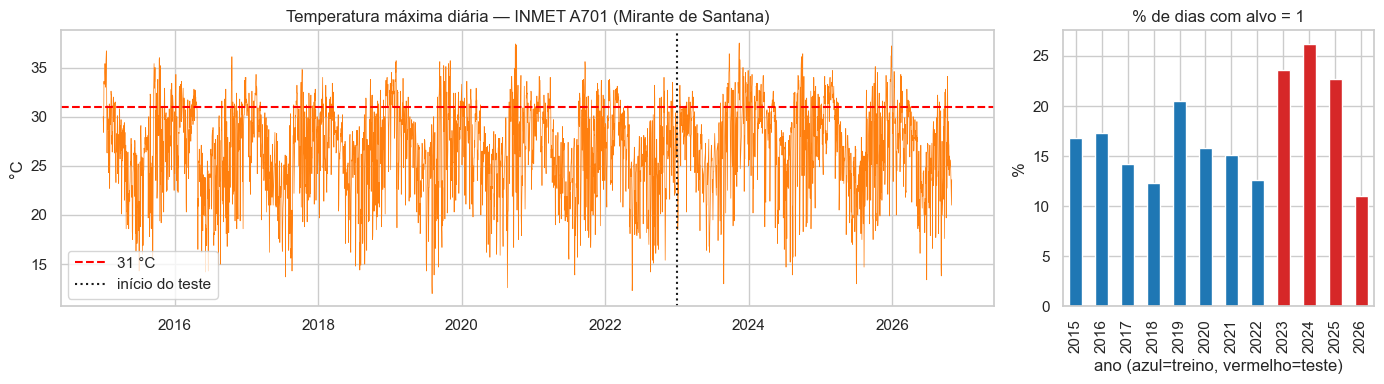

In [6]:
tmax_treino = base.loc[:FIM_TREINO, "tmax"]
print(f"percentil de 31 °C nas máximas de 2015–2022: {(tmax_treino < LIMIAR_C).mean():.1%}")
print("máxima média por mês (2015–2022):")
print(tmax_treino.groupby(tmax_treino.index.month).mean().round(1).to_frame("tmax média °C").T)

fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})
ax[0].plot(base.index, base["tmax"], lw=0.5, color="tab:orange")
ax[0].axhline(LIMIAR_C, color="red", ls="--", label="31 °C")
ax[0].axvline(pd.Timestamp(FIM_TREINO), color="k", ls=":", label="início do teste")
ax[0].set(title="Temperatura máxima diária — INMET A701 (Mirante de Santana)", ylabel="°C")
ax[0].legend()
por_ano = base.groupby(base.index.year)["calor_amanha"].mean() * 100
por_ano.plot.bar(ax=ax[1], color=["tab:blue" if a <= 2022 else "tab:red" for a in por_ano.index])
ax[1].set(title="% de dias com alvo = 1", xlabel="ano (azul=treino, vermelho=teste)", ylabel="%")
plt.tight_layout(); plt.savefig(FIG / "01_serie_tmax.png", dpi=120); plt.show()

## 3. Divisão treino / teste

Como é uma série temporal, a divisão é **cronológica**, nunca aleatória (embaralhar deixaria o modelo "ver" dias vizinhos do teste, que são quase iguais):

- **Treino:** 2015 a 2022 (8 anos).
- **Teste:** 01/2023 a 10/2026 — dados que o modelo nunca vê durante o ajuste. É o cenário real: treinar com o passado e prever o futuro.

O gráfico acima já mostra um ponto importante: **os anos de teste são mais quentes** (2023 e 2024 tiveram recordes de calor em SP). O teste é, portanto, mais difícil e mais honesto que um sorteio.

In [7]:
treino, teste = base.loc[:FIM_TREINO], base.loc[pd.Timestamp(FIM_TREINO) + pd.Timedelta(days=1):]
X_tr, y_tr = treino[FEATURES], treino["calor_amanha"]
X_te, y_te = teste[FEATURES], teste["calor_amanha"]
pd.DataFrame({"período": [f"{treino.index.min():%d/%m/%Y} – {treino.index.max():%d/%m/%Y}",
                          f"{teste.index.min():%d/%m/%Y} – {teste.index.max():%d/%m/%Y}"],
              "dias": [len(treino), len(teste)],
              "% calor forte": [y_tr.mean() * 100, y_te.mean() * 100]}, index=["treino", "teste"]).round(1)

,período,dias,% calor forte
treino,03/01/2015 – 31/12/2022,2906,15.6
teste,01/01/2023 – 30/10/2026,1331,21.3


## 4. Modelo: Random Forest

**Por que Random Forest** (entre XGBoost, Random Forest, MLP, LSTM e KMeans+PCA):

- Os dados são **tabulares e pequenos** (~3 mil dias). Árvores lidam bem com isso; MLP e LSTM precisariam de muito mais dados e de normalização, e tendem a decorar a série.
- Captura **relações não lineares** (ex.: calor só sobe se o dia está seco *e* a pressão caindo) sem precisarmos criar essas combinações à mão.
- É **robusto a overfitting** por construção (média de muitas árvores com amostras diferentes) e tem poucos hiperparâmetros importantes, o que deixa a busca clara.
- Dá **importância das variáveis**, o que ajuda a explicar o alerta para quem não é técnico.
- `class_weight="balanced"` compensa o desbalanceamento (só ~17 % dos dias são positivos).
- XGBoost costuma empatar ou ganhar por pouco nesse tamanho de dados, mas exige mais ajuste fino; a interpretabilidade e a estabilidade da Random Forest pesaram mais para um sistema de alerta público.

**KMeans+PCA** não serve aqui porque temos um alvo definido (é supervisionado).

### Busca de hiperparâmetros (validação cruzada só no treino)

Testamos **3 hiperparâmetros × 24 combinações**:

| hiperparâmetro | valores | o que controla |
|---|---|---|
| `n_estimators` | 100, 300 | nº de árvores |
| `max_depth` | 4, 8, 16, sem limite | profundidade (complexidade) de cada árvore |
| `min_samples_leaf` | 1, 5, 20 | mínimo de dias em cada folha (suaviza a árvore) |

Validação cruzada: `TimeSeriesSplit` com 5 dobras **dentro do treino** — cada dobra treina com os anos anteriores e valida no período seguinte, respeitando o tempo. O conjunto de teste não participa da escolha.

**Métrica de escolha: F1 da classe "calor forte"**. Acurácia engana (um modelo que sempre diz "não" acerta ~83 %); o F1 equilibra *precisão* (não dar alarme falso demais, senão o cidadão ignora) e *recall* (não deixar de avisar num dia de calor).

In [8]:
grade = {"n_estimators": [100, 300], "max_depth": [4, 8, 16, None], "min_samples_leaf": [1, 5, 20]}
cv = TimeSeriesSplit(n_splits=5)
busca = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
    grade, cv=cv, scoring={"f1": "f1", "roc_auc": "roc_auc", "recall": "recall", "precision": "precision"},
    refit="f1", return_train_score=True)
busca.fit(X_tr, y_tr)

res = pd.DataFrame(busca.cv_results_)
tabela = res[["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
              "mean_train_f1", "mean_test_f1", "std_test_f1", "mean_test_roc_auc",
              "mean_test_recall", "mean_test_precision", "rank_test_f1"]].copy()
tabela.columns = ["n_estimators", "max_depth", "min_samples_leaf", "F1 treino (CV)", "F1 validação (CV)",
                  "desvio F1 val", "ROC-AUC val", "recall val", "precisão val", "rank"]
tabela["max_depth"] = tabela["max_depth"].astype(object).where(tabela["max_depth"].notna(), "None")
tabela["gap treino-val"] = tabela["F1 treino (CV)"] - tabela["F1 validação (CV)"]
print(f"{len(tabela)} combinações × {cv.n_splits} dobras = {len(tabela) * cv.n_splits} treinos")
print("melhor combinação:", busca.best_params_, f"| F1 validação = {busca.best_score_:.3f}")
tabela.sort_values("rank").reset_index(drop=True)

24 combinações × 5 dobras = 120 treinos
melhor combinação: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 300} | F1 validação = 0.649


,n_estimators,max_depth,min_samples_leaf,F1 treino (CV),F1 validação (CV),desvio F1 val,ROC-AUC val,recall val,precisão val,rank,gap treino-val
0,300,None,5,0.862,0.649,0.027,0.918,0.715,0.595,1,0.213
1,300,16,5,0.861,0.649,0.027,0.919,0.715,0.594,2,0.213
2,300,8,5,0.818,0.643,0.038,0.918,0.728,0.578,3,0.174
3,100,16,5,0.858,0.642,0.030,0.917,0.710,0.586,4,0.216
4,100,None,5,0.858,0.642,0.030,0.917,0.710,0.586,4,0.216
5,100,8,5,0.818,0.641,0.039,0.918,0.731,0.572,6,0.176
6,100,8,1,0.869,0.633,0.026,0.915,0.675,0.599,7,0.236
7,300,8,1,0.873,0.630,0.030,0.917,0.673,0.597,8,0.243
8,300,4,1,0.712,0.619,0.044,0.915,0.785,0.511,9,0.093
9,300,4,5,0.704,0.618,0.045,0.916,0.799,0.504,10,0.086


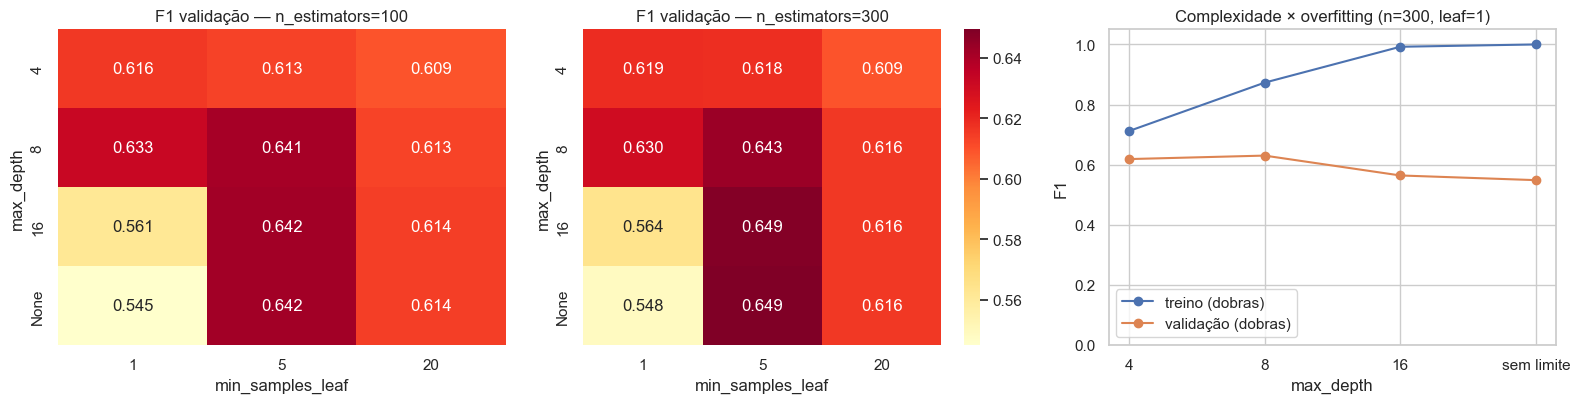

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for i, n in enumerate(grade["n_estimators"]):
    piv = tabela[tabela["n_estimators"] == n].pivot(index="max_depth", columns="min_samples_leaf",
                                                    values="F1 validação (CV)")
    piv = piv.reindex([4, 8, 16, "None"])
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="YlOrRd", ax=ax[i], vmin=tabela["F1 validação (CV)"].min(),
                vmax=tabela["F1 validação (CV)"].max(), cbar=i == 1)
    ax[i].set_title(f"F1 validação — n_estimators={n}")
# curva de complexidade: treino x validação conforme a profundidade (n=300, leaf=1)
curva = tabela[(tabela["n_estimators"] == 300) & (tabela["min_samples_leaf"] == 1)].copy()
x = ["4", "8", "16", "sem limite"]
ax[2].plot(x, curva["F1 treino (CV)"], "o-", label="treino (dobras)")
ax[2].plot(x, curva["F1 validação (CV)"], "o-", label="validação (dobras)")
ax[2].set(title="Complexidade × overfitting (n=300, leaf=1)", xlabel="max_depth", ylabel="F1", ylim=(0, 1.05))
ax[2].legend()
plt.tight_layout(); plt.savefig(FIG / "02_busca_hiperparametros.png", dpi=120); plt.show()

A curva da direita mostra o overfitting clássico: quanto mais profunda a árvore, mais o F1 de **treino** se aproxima de 1 (o modelo decora os dias de treino), enquanto o F1 de **validação** para de subir ou cai. A busca escolhe a combinação com melhor validação, não a de melhor treino.

## 5. Resultados: treino × teste lado a lado

Treinamos o melhor modelo em todo o treino (2015–2022) e avaliamos no teste (2023–2026). Para ter uma referência honesta, comparamos com uma **regra de persistência** — "amanhã vai ser como hoje" (se hoje passou de 31 °C, avisa) — que é o que uma pessoa faria sem modelo.

**Limiar do alerta.** O modelo devolve uma probabilidade; o padrão é avisar quando ela passa de 0,5. Para um alerta de saúde, deixar de avisar num dia quente é pior que um alarme falso, então definimos a política *"avisar em pelo menos 8 de cada 10 dias de calor forte"* e escolhemos o limiar que cumpre isso **nas dobras de validação do treino** (probabilidades fora da amostra, mesmas 5 dobras da busca). O teste continua intocado nessa escolha.

In [10]:
modelo = busca.best_estimator_

# probabilidades fora da amostra no treino (cada dia de validação previsto por um modelo que não o viu)
oof_p, oof_y = [], []
for i_tr, i_val in cv.split(X_tr):
    m = RandomForestClassifier(**busca.best_params_, class_weight="balanced", random_state=SEED)
    m.fit(X_tr.iloc[i_tr], y_tr.iloc[i_tr])
    oof_p.append(m.predict_proba(X_tr.iloc[i_val])[:, 1]); oof_y.append(y_tr.iloc[i_val])
oof_p, oof_y = np.concatenate(oof_p), pd.concat(oof_y)
candidatos = np.round(np.arange(0.05, 0.96, 0.01), 2)
LIMIAR_ALERTA = max(t for t in candidatos if recall_score(oof_y, oof_p >= t) >= 0.80)
print(f"limiar escolhido na validação do treino: {LIMIAR_ALERTA:.2f} "
      f"(recall na validação = {recall_score(oof_y, oof_p >= LIMIAR_ALERTA):.3f}, "
      f"precisão = {precision_score(oof_y, oof_p >= LIMIAR_ALERTA):.3f})")

def metricas(y, pred, prob):
    return {"acurácia": accuracy_score(y, pred), "precisão": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, prob) if prob is not None else np.nan}

p_tr, p_te = modelo.predict_proba(X_tr)[:, 1], modelo.predict_proba(X_te)[:, 1]
persist_tr = (treino["tmax"] >= LIMIAR_C).astype(int)
persist_te = (teste["tmax"] >= LIMIAR_C).astype(int)

comparacao = pd.DataFrame({
    "RF — treino": metricas(y_tr, (p_tr >= 0.5).astype(int), p_tr),
    "RF — validação cruzada": {"F1": busca.best_score_,
                               "ROC-AUC": res.loc[busca.best_index_, "mean_test_roc_auc"],
                               "recall": res.loc[busca.best_index_, "mean_test_recall"],
                               "precisão": res.loc[busca.best_index_, "mean_test_precision"]},
    "RF — teste": metricas(y_te, (p_te >= 0.5).astype(int), p_te),
    f"RF limiar {LIMIAR_ALERTA:.2f} — treino": metricas(y_tr, (p_tr >= LIMIAR_ALERTA).astype(int), p_tr),
    f"RF limiar {LIMIAR_ALERTA:.2f} — teste": metricas(y_te, (p_te >= LIMIAR_ALERTA).astype(int), p_te),
    "Persistência — teste": metricas(y_te, persist_te, None),
}).round(3)
comparacao

limiar escolhido na validação do treino: 0.36 (recall na validação = 0.807, precisão = 0.515)


,RF — treino,RF — validação cruzada,RF — teste,RF limiar 0.36 — treino,RF limiar 0.36 — teste,Persistência — teste
acurácia,0.951,NaN,0.855,0.916,0.844,0.856
precisão,0.776,0.595,0.647,0.650,0.599,0.663
recall,0.965,0.715,0.704,1.000,0.810,0.658
F1,0.860,0.649,0.675,0.788,0.689,0.661
ROC-AUC,0.991,0.918,0.911,0.991,0.911,NaN


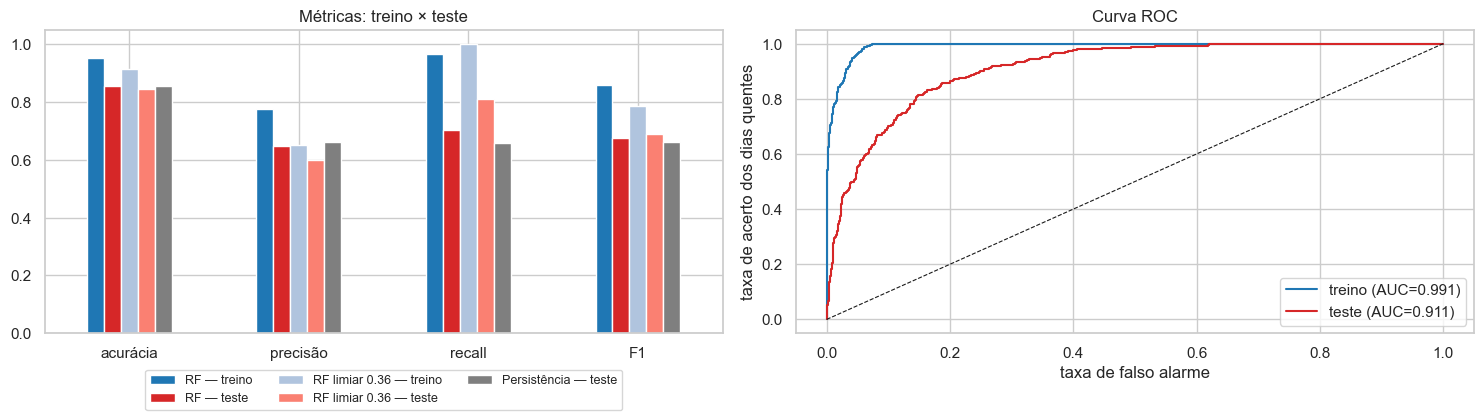

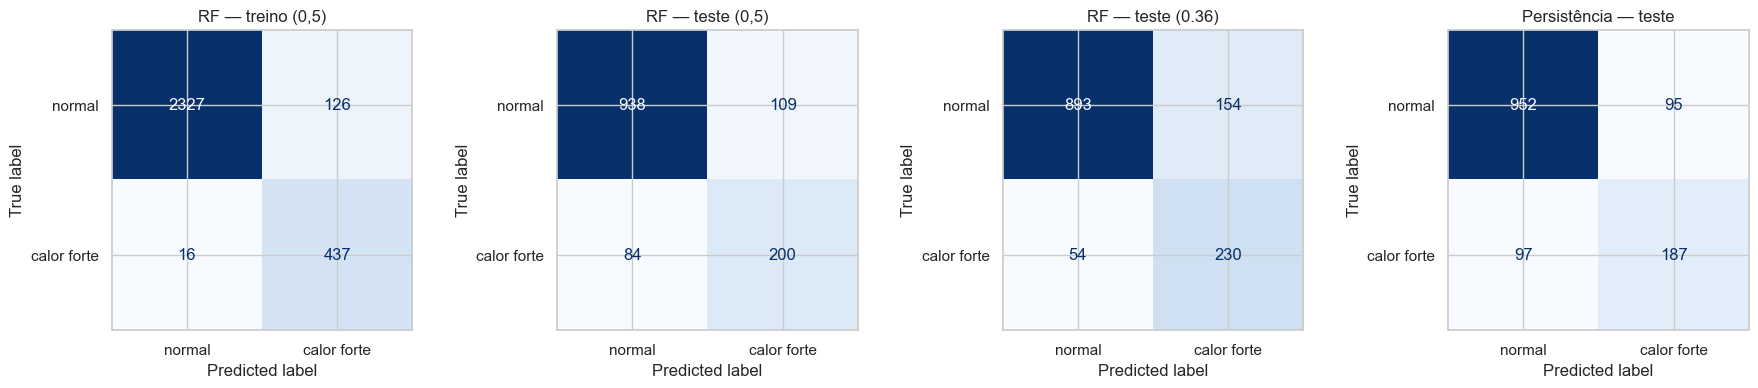

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
comparacao[["RF — treino", "RF — teste", f"RF limiar {LIMIAR_ALERTA:.2f} — treino",
            f"RF limiar {LIMIAR_ALERTA:.2f} — teste", "Persistência — teste"]].drop(index="ROC-AUC").plot.bar(
    ax=ax[0], rot=0, color=["tab:blue", "tab:red", "lightsteelblue", "salmon", "tab:gray"])
ax[0].set(title="Métricas: treino × teste", ylim=(0, 1.05))
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=9)
for nome, y, p, cor in [("treino", y_tr, p_tr, "tab:blue"), ("teste", y_te, p_te, "tab:red")]:
    fpr, tpr, _ = roc_curve(y, p)
    ax[1].plot(fpr, tpr, color=cor, label=f"{nome} (AUC={roc_auc_score(y, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set(title="Curva ROC", xlabel="taxa de falso alarme", ylabel="taxa de acerto dos dias quentes")
ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "03_treino_vs_teste.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, (nome, y, pred) in zip(ax, [("RF — treino (0,5)", y_tr, (p_tr >= 0.5).astype(int)),
                                   ("RF — teste (0,5)", y_te, (p_te >= 0.5).astype(int)),
                                   (f"RF — teste ({LIMIAR_ALERTA:.2f})", y_te, (p_te >= LIMIAR_ALERTA).astype(int)),
                                   ("Persistência — teste", y_te, persist_te)]):
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["normal", "calor forte"]).plot(
        ax=a, colorbar=False, cmap="Blues")
    a.set_title(nome)
plt.tight_layout(); plt.savefig(FIG / "04_matrizes_confusao.png", dpi=120); plt.show()

### Onde o modelo ganha da regra "amanhã igual a hoje"

A temperatura de amanhã se parece muito com a de hoje, então a persistência já acerta boa parte dos dias. O que ela **nunca** faz é avisar o **primeiro dia** de uma onda de calor (hoje ainda não passou de 31 °C), e ela sempre erra o **dia em que a onda acaba** (avisa e não faz calor). São justamente esses dias que o modelo precisa resolver.

In [12]:
inicio = (teste["tmax"] < LIMIAR_C) & (y_te == 1)   # hoje normal, amanhã calor forte
fim = (teste["tmax"] >= LIMIAR_C) & (y_te == 0)     # hoje calor forte, amanhã normal
alerta_05, alerta_aj = p_te >= 0.5, p_te >= LIMIAR_ALERTA
pd.DataFrame({
    "1º dia da onda: avisou (de %d)" % inicio.sum(): [0, (alerta_05 & inicio).sum(), (alerta_aj & inicio).sum()],
    "fim da onda: alarme falso (de %d)" % fim.sum(): [fim.sum(), (alerta_05 & fim).sum(), (alerta_aj & fim).sum()],
    "dias de calor avisados (de %d)" % y_te.sum(): [(persist_te & y_te).sum(), (alerta_05 & (y_te == 1)).sum(),
                                                    (alerta_aj & (y_te == 1)).sum()],
    "alarmes falsos no total": [(persist_te & (y_te == 0)).sum(), (alerta_05 & (y_te == 0)).sum(),
                                (alerta_aj & (y_te == 0)).sum()],
}, index=["Persistência", "RF limiar 0,5", f"RF limiar {LIMIAR_ALERTA:.2f}"])

,1º dia da onda: avisou (de 97),fim da onda: alarme falso (de 95),dias de calor avisados (de 284),alarmes falsos no total
Persistência,0,95,187,95
"RF limiar 0,5",26,74,200,109
RF limiar 0.36,45,85,230,154


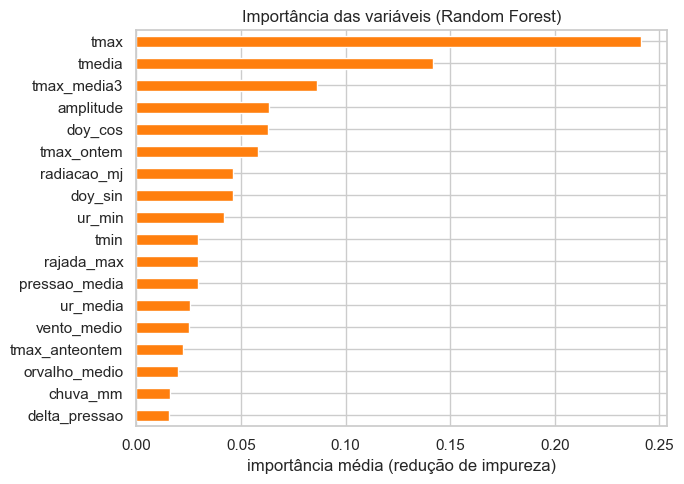

,tmax,tmedia,tmax_media3,amplitude,doy_cos,tmax_ontem
importância,0.241,0.142,0.086,0.063,0.063,0.058


In [13]:
imp = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp.plot.barh(ax=ax, color="tab:orange")
ax.set(title="Importância das variáveis (Random Forest)", xlabel="importância média (redução de impureza)")
plt.tight_layout(); plt.savefig(FIG / "05_importancia.png", dpi=120); plt.show()
imp.sort_values(ascending=False).head(6).round(3).to_frame("importância").T

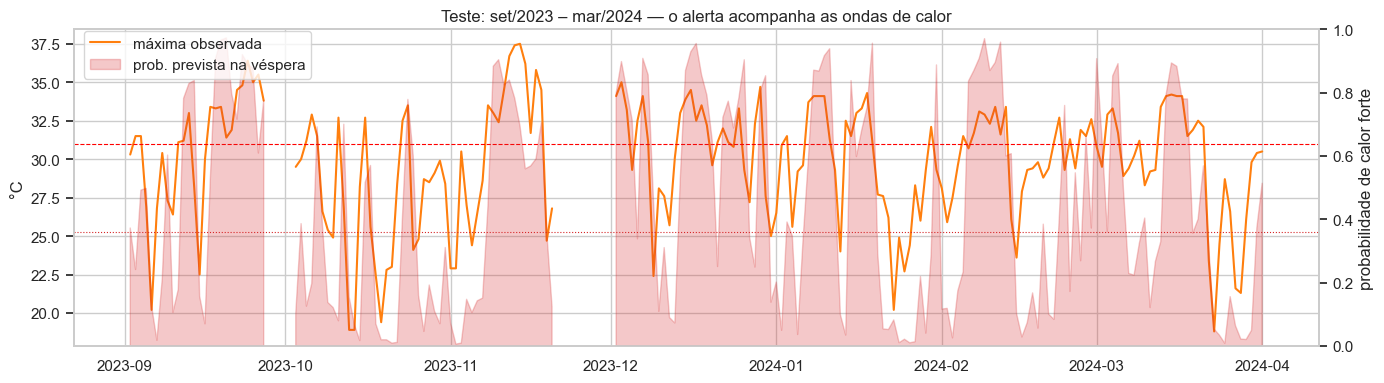

In [14]:
# exemplo de uso real: verão 2023/2024 no teste, probabilidade prevista na véspera × o que aconteceu
janela = teste.loc["2023-09-01":"2024-03-31"].asfreq("D")  # dias sem dado viram buracos no gráfico
prob = pd.Series(p_te, index=teste.index).reindex(janela.index)
fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(janela.index + pd.Timedelta(days=1), janela["tmax_amanha"], color="tab:orange", label="máxima observada")
ax1.axhline(LIMIAR_C, color="red", ls="--", lw=0.8)
ax1.set_ylabel("°C")
ax2 = ax1.twinx()
ax2.fill_between(prob.index + pd.Timedelta(days=1), prob, alpha=0.25, color="tab:red", label="prob. prevista na véspera")
ax2.axhline(LIMIAR_ALERTA, color="tab:red", ls=":", lw=0.8)
ax2.set(ylim=(0, 1), ylabel="probabilidade de calor forte"); ax2.grid(False)
ax1.set_title("Teste: set/2023 – mar/2024 — o alerta acompanha as ondas de calor")
fig.legend(loc="upper left", bbox_to_anchor=(0.06, 0.92))
plt.tight_layout(); plt.savefig(FIG / "06_exemplo_verao.png", dpi=120); plt.show()

## 6. Discussão de overfitting e conclusão

In [15]:
r = comparacao
gap = r.loc["F1", "RF — treino"] - r.loc["F1", "RF — teste"]
print(f"F1 treino {r.loc['F1', 'RF — treino']:.3f} | F1 validação cruzada {r.loc['F1', 'RF — validação cruzada']:.3f}"
      f" | F1 teste {r.loc['F1', 'RF — teste']:.3f} | gap treino-teste {gap:.3f}")
print(f"ROC-AUC treino {r.loc['ROC-AUC', 'RF — treino']:.3f} | teste {r.loc['ROC-AUC', 'RF — teste']:.3f}")
print(f"F1 persistência no teste {r.loc['F1', 'Persistência — teste']:.3f}"
      f" -> ganho do modelo: {r.loc['F1', 'RF — teste'] - r.loc['F1', 'Persistência — teste']:+.3f}")
for lim in [0.5, LIMIAR_ALERTA]:
    tn, fp, fn, tp = confusion_matrix(y_te, (p_te >= lim).astype(int)).ravel()
    print(f"[limiar {lim:.2f}] No teste houve {tp + fn} dias de calor forte; o modelo avisou na véspera em {tp}"
          f" ({tp/(tp+fn):.0%}), deixou passar {fn} e deu {fp} alarmes falsos em {tn + fp} dias normais"
          f" ({fp/(tn+fp):.0%}); de cada 10 alertas, {10 * tp / (tp + fp):.1f} se confirmaram.")

F1 treino 0.860 | F1 validação cruzada 0.649 | F1 teste 0.675 | gap treino-teste 0.185
ROC-AUC treino 0.991 | teste 0.911
F1 persistência no teste 0.661 -> ganho do modelo: +0.014
[limiar 0.50] No teste houve 284 dias de calor forte; o modelo avisou na véspera em 200 (70%), deixou passar 84 e deu 109 alarmes falsos em 1047 dias normais (10%); de cada 10 alertas, 6.5 se confirmaram.
[limiar 0.36] No teste houve 284 dias de calor forte; o modelo avisou na véspera em 230 (81%), deixou passar 54 e deu 154 alarmes falsos em 1047 dias normais (15%); de cada 10 alertas, 6.0 se confirmaram.


**Overfitting.** Há overfitting, e ele está sob controle:

- No treino o modelo escolhido tem F1 0,86 e ROC-AUC 0,99; na validação cruzada, F1 0,65 e AUC 0,92; no teste, F1 0,68 e AUC 0,91. A distância treino → teste (~0,19 de F1) é típica de Random Forest, que se ajusta muito aos dias que viu.
- O sinal de que isso **não atrapalha** é que validação cruzada e teste ficam praticamente iguais: o desempenho estimado só com o treino se confirmou em quase 4 anos nunca vistos, que ainda por cima foram mais quentes (21 % de dias quentes no teste contra 16 % no treino).
- A busca mostrou o overfitting quando ele é ruim: com `min_samples_leaf=1` e árvores profundas o F1 de treino vai a 1,00 e o de validação cai para 0,55. A combinação escolhida (`min_samples_leaf=5`) suaviza as folhas e tem o melhor F1 de validação. Folhas de 20 dias já "esquecem" demais (underfitting, F1 0,61).

**Comparação honesta.** Com o limiar padrão de 0,5, o modelo fica só um pouco acima da regra "amanhã igual a hoje" (F1 0,68 contra 0,66), porque a temperatura tem muita inércia. O ganho real aparece onde o cidadão mais precisa: o modelo avisa **45 dos 97 primeiros dias de ondas de calor** do teste (a regra simples avisa zero, por definição) e, com o limiar de 0,36 escolhido no treino, cobre **81 % dos dias quentes** contra 66 % da regra simples.

**Para o cidadão.** Com os dados de hoje do INMET, a SombraSP consegue avisar **na véspera** cerca de 8 em cada 10 dias de calor forte no Centro. Em troca, cerca de 4 em cada 10 alertas são "falsos" — dias que ficaram quentes, mas abaixo de 31 °C. Para um alerta de saúde essa troca é aceitável: o custo de um aviso a mais é levar uma garrafa de água à toa; o custo de um aviso a menos é um idoso ou ambulante passar o dia no sol sem se preparar. Na prática, a mensagem chega à noite: *"amanhã deve passar de 31 °C: leve água, evite o sol das 11h às 16h, veja os pontos de sombra e hidratação perto de você"*.

**Limites e próximos passos.** É uma única estação (Mirante de Santana, zona norte), mais fresca que o asfalto da Sé/República; por isso a SombraSP combina este modelo com os sensores ESP32 locais (Physical Computing). O modelo só olha o passado da própria estação; incluir a previsão numérica do tempo e outras estações do INMET da Grande SP deve melhorar principalmente o aviso do primeiro dia das ondas.